## NLP from first principles 

This notebook contains small experiements / visualization of some concepts of NLP.  
The goal is to understand how things work, there is no use of LLMs (the code will be messy).  
It will follow the course [foundations of LLMs](https://www.master-mva.com/cours/foundations-of-large-language-models/) by N. Fijalkow and D. Louapre 

### Language modeling : markov chain on text8 data set

Steps to build a markov chain model :

1) Get clean data
2) Define a finite vocabulary using N-grams 
3) Learn (estimate) transition matrix from data 
4) Generate text by walking on the graph 

In [1]:
import numpy as np
from scipy.sparse import coo_matrix
import random as rng
from collections import Counter
import pandas as pd 
import mmap

In [2]:
def load_data():
    with open("data/text8") as f:
        data = f.read().split()

    word_to_index = {word: idx for idx, word in enumerate(set(data))}
    index_to_word = {idx: word for idx, word in enumerate(set(data))}
    print("Size of data (in tokens):", len(data))
    print("Size of vocabulary:", len(word_to_index))

    return data, word_to_index, index_to_word

data, vocab, index_to_word = load_data()

Size of data (in tokens): 17005207
Size of vocabulary: 253854


We want to build transition matrix $P$ such that $P_{i,j}$ is the probability that word $j$ follows word $j$ (1-gram model)

Problem : the size of $P$ is $|V|^2$. But it's very sparse because of the structure of the language. That's why we're using sparse matrix representation from scipy 

In [3]:
def transition_matrix(data, vocab):
    n, d = len(data), len(vocab)
    row, col, values = [], [], []

    for i in range(n-1):
        row.append(vocab[data[i]])
        col.append(vocab[data[i+1]])
        values.append(1)
    
    P = coo_matrix((values, (row, col)), shape=(d, d)).tocsr()
    row_sums = np.asarray(P.sum(axis=1)).ravel()
    P = P.multiply((1 / row_sums)[:, None])
    return P.tocsr()

P = transition_matrix(data, vocab)

In [4]:
def inference(P, vocab, index_to_word, initial_seq, seq_len, seed = 67):
    
    rng = np.random.default_rng(seed)
    if initial_seq in vocab.keys():   # check wheter initial_seq is in vocab

        seq = [initial_seq]
        while len(seq) <= seq_len:
            probs = P.getrow(vocab[seq[-1]])     # get probability distribution of state seq[i-1]
            next_token_index = rng.choice(probs.indices, p=probs.data)   # sample from distribution the next token
            seq.append(index_to_word[next_token_index])
        return seq

    else:
        raise ValueError("Initial sequence not in vocabulary. Try again.")

Some test

In [5]:
initial_seq = "quentin"
answer = " ".join(inference(P, vocab, index_to_word, initial_seq, 15))

print("Prompt : ", initial_seq)
print("Answer :", answer)

initial_seq = "goat"
answer = " ".join(inference(P, vocab, index_to_word, initial_seq, 15))

print("Prompt : ", initial_seq)
print("Answer :", answer)

initial_seq = "shakespeare"
answer = " ".join(inference(P, vocab, index_to_word, initial_seq, 30))

print("Prompt : ", initial_seq)
print("Answer :", answer)

Prompt :  quentin
Answer : quentin one four one nine one nine seven nine eight five seven km countries and had
Prompt :  goat
Answer : goat which could be accurately explain one nine two four flo conway bangs is used heavily
Prompt :  shakespeare
Answer : shakespeare s thus part of the hypothesis james version going into a job and when boas considered film only a form of tunisia seven births nine aston martin paul horowitz marks


In [6]:
print("index size : ", P.nnz)

# Size of transition space is instead of |V|^2 = 64B 

index size :  4146848


There is a lot of things to try : implement smartly N-grams and compare perplexity for N = 1,2, 3... 

Intuitively : if $N$ is big but our data size stays the same, many sequences $(w_1, .., w_N)$ will be observed only once, and so we will always get the same answer BUT more accurate since closer to real data text (more context) ! 

### Bag of word and classifier

Steps : 

1) Define a vocabulary (e.g. top K highest token frequency in the dataset)
2) Write an encoder using bag of word 
3) Train a binary classifier
4) Do inference

In [7]:
imdb_data = pd.read_csv("data/IMDB Dataset.csv")

imdb_data

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [8]:
import re
VOC_SIZE = 5_000

def tokenize(text):
    """
    I had problem with raw data like 'way.' and 'way' are 2 different tokens.
    So I decided to do preprocessing to remove ponctuation. 
    (Yes I used an LLM to do the regex for me)
    """
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    return re.findall(r"\b[\w']+\b", text)

def create_vocab(texts, size=10_000):
    counter = Counter()
    document_freq = Counter()
    for text in texts:
        tokens = tokenize(text)
        counter.update(tokens)
        document_freq.update(set(tokens))

    vocab = {}
    for word, _ in counter.most_common(size):
        vocab[word] = len(vocab)

    return vocab, counter, document_freq

vocab_imdb, counter_imdb, df_imdb = create_vocab(imdb_data["review"], size = VOC_SIZE)

In [9]:
def bow_encoder(sequence, vocab):      # bag of word encoder
    encoded = np.zeros(len(vocab))
    for word in tokenize(sequence):
        if word in vocab:
            encoded[vocab[word]] += 1
    return encoded

test_vector = bow_encoder("this is the best test possible in the world", vocab_imdb)
print(test_vector)
print(test_vector.sum())

[2. 0. 0. ... 0. 0. 0.]
9.0


In [10]:
def tf_idf_encoder(sequence, vocab, df, n_documents):
    encoded = np.zeros(len(vocab))
    tokens = tokenize(sequence)
    counts = Counter(tokens)
    total_tokens = len(tokens)
    for word, count in counts.items():
        if word in vocab:
            tf = count / total_tokens
            idf = np.log(n_documents / df[word])
            encoded[vocab[word]] = tf * idf
    return encoded
    
test_vector = tf_idf_encoder("this is the best test possible in the world", vocab_imdb, df_imdb, len(imdb_data))
print(test_vector)
print(test_vector.sum())

# remark : "the" is almost 0 because it is very present in the corpus. 
# indeed, it doesn't really give us information about the review like "exceptionnal" or "tremendous"

[0.00195973 0.         0.         ... 0.         0.         0.        ]
1.3707948067496045


In [11]:
# Compute embeddings for each review

imdb_data["label"] = imdb_data["sentiment"].apply(lambda x: 0 if x == "negative" else 1)
imdb_data["bow_encoded"] = imdb_data["review"].apply(lambda x: bow_encoder(x, vocab = vocab_imdb))
imdb_data["tf_idf_encoded"] = imdb_data["review"].apply(lambda x: tf_idf_encoder(x, vocab_imdb, df_imdb, len(imdb_data)))

X_bow =  np.stack(imdb_data["bow_encoded"].values)
X_tf_idf = np.stack(imdb_data["tf_idf_encoded"].values)
y = imdb_data["label"].values

#


Note : it's quite slow because we're building big matrices (|V|x n) where n is the length of the dataset. 

But those embeddings are very sparse. We should use COO matrices to accelerate computations. 

Implement it if you don't have a lot of memory.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

indices = np.arange(len(imdb_data))
idx_train, idx_test = train_test_split(indices, test_size=0.2, random_state=42)

X_train = X_bow[idx_train]
X_test  = X_bow[idx_test]

y_train = y[idx_train]
y_test  = y[idx_test]
clf_bow = LogisticRegression(max_iter = 1000, random_state=0).fit(X_train, y_train)
print("train accuracy bow embeddings : ",clf_bow.score(X_train, y_train))
print("test accuracy bow embeddings : ",clf_bow.score(X_test, y_test))

train accuracy bow embeddings :  0.943
test accuracy bow embeddings :  0.8778


Let's see some false positives : are they sarcastic ? Using "positive" words ironically ? 

In [14]:
y_pred = clf_bow.predict(X_test)
fp_indices = np.where((y_pred == 1) & (y_test == 0))[0] # false positives

fp_indices_original = idx_test[fp_indices]
imdb_data.iloc[fp_indices_original[:10]][["review", "sentiment"]]

,review,sentiment
4144,I was very disappointed with this series. It h...,negative
37237,I'm writing this note as a chess player as wel...,negative
24712,A ruthless assassin has been hired to eliminat...,negative
34657,"In fact, parts of it I liked a lot. It had som...",negative
46734,"OK, imagine that every state in the US, nay, e...",negative
48492,Spinal Tap was funny because if you knew a lit...,negative
17893,I saw this film in the movie theater. I was ta...,negative
38242,"I'm not to keen on The Pallbearer, it's not to...",negative
3862,It's telling that as of the entry of this comm...,negative
30092,The movie is about two brothers that are suppo...,negative


In [17]:

X_train = X_tf_idf[idx_train]
X_test  = X_tf_idf[idx_test]

clf_tf_idf = LogisticRegression(max_iter = 1000, random_state=0).fit(X_train, y_train)
print("train accuracy tf-idf embeddings : ",clf_tf_idf.score(X_train, y_train))
print("test accuracy tf-idf embeddings : ",clf_tf_idf.score(X_test, y_test))

train accuracy tf-idf embeddings :  0.879075
test accuracy tf-idf embeddings :  0.8747


In [18]:
index_to_word = {idx: word for word, idx in vocab_imdb.items()}

def show_important_words(clf, index_to_word, k=20):
    weights = clf.coef_[0]

    positive = np.argsort(weights)[-k:][::-1]
    negative = np.argsort(weights)[:k]

    print("most positive words:")
    for idx in positive:
        print(f"{index_to_word[idx]:20s} {weights[idx]}")

    print("most negative words:")
    for idx in negative:
        print(f"{index_to_word[idx]:20s} {weights[idx]}")

show_important_words(clf_bow, index_to_word)
show_important_words(clf_tf_idf, index_to_word)

most positive words:
refreshing           2.2590477775372704
7                    1.8555453804909388
pleased              1.7901584091715073
hooked               1.4736228040036785
ideal                1.4346604590723822
conventional         1.4195350197525534
wonderfully          1.4134079233801622
nevertheless         1.390687671769604
complaint            1.3873467899835272
definite             1.3682618603116432
appreciated          1.354413647503528
vengeance            1.3530106118024325
plant                1.34979384993848
facing               1.3482677042871065
blues                1.3358789827258992
finest               1.3303490662895163
delightful           1.3190758647058014
identify             1.3084903267397294
pitch                1.3076535673460177
complain             1.3060390607132362
most negative words:
mst3k                -2.6010235300874793
stinker              -2.561200331417754
waste                -2.188873986410689
forgettable          -2.0534745348033208


I don't want to dive deeper into the regressions (different regularization, cross validation...) but we can already see some promising results !   

The accuracy is almost the same between BoW and TF-IDF embeddings, around 0.88 on the same test set (10k samples) which is pretty good for such a simple model !  It's quite surprising, one would expect TF-IDF to overperform BoW since the embeddings already give more information about the "information" given by tokens. 

Looking at the coefficients of the regression, we really see positive words being heavily rewarded (e.g. "pleased", "appreciated", "refreshing") and negative ("waste", "worse", "boring") so that's interesting ! 


Ablation with vocabulary size $|V|$ : 


| Taille du vocabulaire $\lvert V\rvert$ | Accuracy BoW | Accuracy TF-IDF |
|--------------------------------------:|-------------:|----------------:|
| 1 000                                 | 84 %         | 84 %            |
| 5 000                                 | 88 %         | 87 %            |
| 10 000                                | 88 %         | 87 %            |
| 20 000                                | 88 %         | 88 %            |

Note : It looks like BoW tends to overfit way more quickly than TF-IDF on big vocabulary size. 


### Pure logistic regression VS small NN 

In [20]:
import torch
from torch import nn
from torch.utils.data import DataLoader

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


In [21]:
class SmallNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(VOC_SIZE, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(), 
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [22]:
# training loop for BoW encoding 
model = SmallNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

X_train, X_test, y_train, y_test = train_test_split(X_bow, y, test_size=0.2, random_state=42)
X_train = torch.from_numpy(X_train).float().to(device)
y_train = torch.from_numpy(y_train).float().to(device)

EPOCH = 100
for epoch in range(EPOCH):
    model.train()

    logits = model(X_train)
    loss = criterion(logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print("Epoch [{}] Loss: {:.4f}".format(epoch, loss.item()))

model.eval()

with torch.no_grad():
    logits = model(X_train)
    probs = torch.sigmoid(logits)
    y_pred_train = (probs > 0.5).float()

with torch.no_grad():
    logits = model(torch.from_numpy(X_test).float().to(device))
    probs = torch.sigmoid(logits)
    y_pred_test = (probs > 0.5).float()

accuracy_train = (y_pred_train == y_train).float().mean()
print("Accuracy Train BoW:", accuracy_train.item())
accuracy_test = (y_pred_test == torch.from_numpy(y_test).float().to(device)).float().mean()
print("Accuracy Test BoW:", accuracy_test.item())

Epoch [0] Loss: 0.6927
Epoch [10] Loss: 0.4079
Epoch [20] Loss: 0.2709
Epoch [30] Loss: 0.2193
Epoch [40] Loss: 0.1903
Epoch [50] Loss: 0.1730
Epoch [60] Loss: 0.1575
Epoch [70] Loss: 0.1424
Epoch [80] Loss: 0.1298
Epoch [90] Loss: 0.1119
Accuracy Train BoW: 0.9722750186920166
Accuracy Test BoW: 0.8787999749183655


In [23]:
# training loop for TF_IDF  encoding 
model = SmallNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

X_train, X_test, y_train, y_test = train_test_split(X_tf_idf, y, test_size=0.2, random_state=42)
X_train = torch.from_numpy(X_train).float().to(device)
y_train = torch.from_numpy(y_train).float().to(device)

EPOCH = 100
for epoch in range(EPOCH):
    model.train()

    logits = model(X_train)
    loss = criterion(logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print("Epoch [{}] Loss: {:.4f}".format(epoch, loss.item()))

model.eval()

with torch.no_grad():
    logits = model(X_train)
    probs = torch.sigmoid(logits)
    y_pred_train = (probs > 0.5).float()

with torch.no_grad():
    logits = model(torch.from_numpy(X_test).float().to(device))
    probs = torch.sigmoid(logits)
    y_pred_test = (probs > 0.5).float()

accuracy_train = (y_pred_train == y_train).float().mean()
print("Accuracy Train TF-IDF:", accuracy_train.item())
accuracy_test = (y_pred_test == torch.from_numpy(y_test).float().to(device)).float().mean()
print("Accuracy Test TF-IDF:", accuracy_test.item())

Epoch [0] Loss: 0.6944
Epoch [10] Loss: 0.6876
Epoch [20] Loss: 0.6668
Epoch [30] Loss: 0.6226
Epoch [40] Loss: 0.5475
Epoch [50] Loss: 0.4518
Epoch [60] Loss: 0.3641
Epoch [70] Loss: 0.3034
Epoch [80] Loss: 0.2656
Epoch [90] Loss: 0.2407
Accuracy Train TF-IDF: 0.9160249829292297
Accuracy Test TF-IDF: 0.8705999851226807


We achieve kind of the same accuracy as a linear regression. 
Looking at predictions that fails, it looks like we're limited by semantic interpretation from the model.. maybe we should use Word2Vec embeddings ? 

In [24]:
MAX_WORDS = 100_000
word2vec_file = "data/GoogleNews-vectors-negative300.bin"

# This function must be studied because it is a very efficient way to read index/embeddings pairs from a binary file.

with open(word2vec_file, "rb") as f:

    data = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)    # loading binary file in memory
    
    header_end = data.find(b'\n')                               # looking for header end
    n_words, dim = map(int, data[:header_end].split())          # from bytes to int 

    # load vectors 
    words = []
    vectors = np.empty((MAX_WORDS, dim), dtype = np.float32)
    pos = header_end + 1                # pointer to first word
    for i in range(MAX_WORDS):          # iterating through the words 
        space = data.find(b" ", pos)    # words are separated by whitespace so we look for the next one
        words.append(data[pos:space].decode("utf-8"))   # conversion to readable utf-8
        pos = space + 1 
        vectors[i] = np.frombuffer(data, dtype = np.float32, count = dim, offset = pos) # reading from buffer, interpreting bytes as float32
        pos += 4 * dim          # float32 is 4 bytes so we move the pointer by 4*dim to get to the next word 

index = {word: i for i,word in enumerate(words)}
embeddings = {word: vectors[index[word]] for word in words}

print("Shape of embedding matrix : ", vectors.shape)
print("First 10 words : ", words[:10])
print("Index of 'token': ", index["7"])
print("Embedding of London : ", embeddings["London"])

Shape of embedding matrix :  (100000, 300)
First 10 words :  ['</s>', 'in', 'for', 'that', 'is', 'on', '##', 'The', 'with', 'said']
Index of 'token':  399
Embedding of London :  [-0.26757812  0.09277344 -0.23828125  0.11523438 -0.00683594  0.22167969
 -0.25195312 -0.05541992  0.02001953  0.14941406 -0.11572266  0.2734375
  0.24902344 -0.11425781  0.05151367 -0.04516602  0.00141144  0.06494141
 -0.03125    -0.2421875  -0.05664062 -0.1328125   0.05517578  0.19433594
  0.27148438  0.203125   -0.00402832  0.2109375  -0.02526855  0.25
  0.12695312  0.04711914 -0.30664062 -0.08935547 -0.16503906  0.08203125
 -0.015625    0.04223633 -0.12597656  0.01281738 -0.07568359 -0.19238281
 -0.18164062  0.22851562 -0.0189209   0.1484375  -0.15136719 -0.02575684
 -0.01721191 -0.04711914  0.13867188  0.17871094  0.30078125 -0.14746094
 -0.19042969  0.00915527 -0.17285156 -0.02502441 -0.30859375 -0.20214844
  0.02209473 -0.12158203  0.04174805  0.06030273 -0.05126953 -0.11181641
 -0.1484375   0.234375    

In [25]:
def similarity_from_vec(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))


def similarity_from_words(w1, w2):
    v1, v2 = embeddings[w1], embeddings[w2]
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

print(similarity_from_words("The", "the"))
print(similarity_from_words("Paris", "France"))
print(similarity_from_words("London", "Paris"))
print(similarity_from_words("cherry", "bear"))

0.44767204
0.63349116
0.52898705
0.1285512


A few funny tests for embeddings arithmetics

In [26]:
def get_closest_words(v, embeddings, k = 5): 
    similarities = {w: similarity_from_vec(v, word_vec) for w, word_vec in embeddings.items()}
    closest_words = sorted(similarities.items(), key=lambda x: x[1], reverse=True)[:k]
    return closest_words

get_closest_words(embeddings["France"], embeddings, k=5)

[('France', np.float32(1.0)),
 ('French', np.float32(0.7000753)),
 ('Belgium', np.float32(0.6933181)),
 ('Paris', np.float32(0.63349116)),
 ('Germany', np.float32(0.6270758))]

In [27]:
wordA = "king"
wordB = "man"
wordC = "woman"

target = embeddings[wordA] - embeddings[wordB] + embeddings[wordC]
print(f"{wordA} - {wordB} + {wordC} = :", get_closest_words(target, embeddings, k = 5))

wordA = "Paris"
wordB = "France"
wordC = "USA"

target = embeddings[wordA] - embeddings[wordB] + embeddings[wordC]
print(f"{wordA} - {wordB} + {wordC} = :", get_closest_words(target, embeddings, k = 5))

wordA = "chess"
wordB = "king"
wordC = "woman"

target = embeddings[wordA] - embeddings[wordB] + embeddings[wordC]
print(f"{wordA} - {wordB} + {wordC} = :", get_closest_words(target, embeddings, k = 5))


king - man + woman = : [('king', np.float32(0.8449394)), ('queen', np.float32(0.73005176)), ('monarch', np.float32(0.6454661)), ('princess', np.float32(0.61562514)), ('crown_prince', np.float32(0.5818678))]
Paris - France + USA = : [('USA', np.float32(0.6500748)), ('Washington_DC', np.float32(0.4423838)), ('Paris', np.float32(0.43230048)), ('Athens_Greece', np.float32(0.38460383)), ('Atlanta_Ga.', np.float32(0.37557927))]
chess - king + woman = : [('chess', np.float32(0.63873106)), ('woman', np.float32(0.5122804)), ('tennis', np.float32(0.40823653)), ('Chess', np.float32(0.40792367)), ('Scrabble', np.float32(0.38047987))]


Back to IMDB Classification with Word2Vec embeddings. 
Aggregation is done by mean pooling (averaging emeddings of all the tokens of the sequence)

In [28]:
def w2v_encoder(sequence, embeddings):
    seq = tokenize(sequence)
    # we take embedding of each token that are in the vocabulary and ignore the rest
    tokens = [embeddings[token] for token in seq if token in embeddings]
    
    # if no tokens are in the vocabulary (e.g. "a a a a a b b b b")
    if len(tokens) == 0:
        return np.zeros(300)

    # mean pooling
    return np.mean(tokens, axis=0)
    
w2v_encoder("this is the best test you have ever seen", embeddings)

array([-3.27453613e-02,  2.77777780e-02,  6.32866770e-02,  1.21676974e-01,
       -5.41720912e-02,  1.91786028e-02, -3.65871843e-03, -5.92447929e-02,
        5.82546666e-02,  1.16912842e-01, -5.27072474e-02, -1.28377274e-01,
        3.28233503e-02,  1.27495662e-03, -3.00632045e-02,  9.68356654e-02,
        7.26114884e-02,  3.08871791e-02,  7.21571175e-03, -7.94559047e-02,
       -3.34031843e-02,  7.24012554e-02, -1.62760413e-03, -8.87730941e-02,
        5.39669469e-02,  8.02951399e-03, -1.06309682e-01,  6.43208846e-02,
        3.46866176e-02,  3.63837332e-02, -1.52621800e-02,  6.51719868e-02,
       -1.41940648e-02, -7.32125156e-03,  6.52465820e-02,  9.21893641e-02,
       -4.37689871e-02, -6.72743022e-02,  8.54458287e-02,  5.34803607e-02,
        4.16259766e-02, -6.49007186e-02,  3.96465734e-02,  2.09181048e-02,
        1.93210170e-02,  5.94499372e-02, -7.52766943e-03,  4.79329415e-02,
        4.57628034e-02, -5.01844613e-03,  5.18324114e-02,  3.93405482e-02,
       -5.89260533e-02,  

In [29]:
imdb_data["word2vec_encoded"] = imdb_data["review"].apply(lambda x : w2v_encoder(x, embeddings))

X_w2v =  np.stack(imdb_data["word2vec_encoded"].values)
X_train, X_test, y_train, y_test = train_test_split(X_w2v, y, test_size=0.2, random_state=42)
clf_w2v = LogisticRegression(max_iter = 2000, random_state=0).fit(X_train, y_train)
print("train accuracy word2vec embeddings : ",clf_w2v.score(X_train, y_train))
print("test accuracy word2vec embeddings : ",clf_w2v.score(X_test, y_test))


train accuracy word2vec embeddings :  0.856225
test accuracy word2vec embeddings :  0.8512


This is not a bad result : we are doing almost as well as BoW BUT with only $d = 300$ which is computationnaly way more efficient ! 
We could try weighted average or concatenation over last $N$. 
Even $N$ = 30 would give $d_{w2v} = 9000 \leq d_{BoW} = |V| = 10000$.  
Another soulution could be to divide the whole sequence in $N$ pieces, and average each piece ! 

In [55]:
def w2v_encoder_lastN(sequence, embeddings, N = 20):
    seq = tokenize(sequence)
    # we take embedding of each token that are in the vocabulary and ignore the rest
    tokens = [embeddings[token] for token in seq if token in embeddings][::-1]
    # Take last N tokens
    tokens = tokens[::-1][-N:]
    # Output vector, zero-padded if |tokens| <N
    v = np.zeros(300 * N)
    # Concatenation
    if len(tokens) > 0:
        v[-len(tokens) * 300:] = np.concatenate(tokens)
    return v

w2v_encoder_lastN("this is the best test you have ever seen", embeddings)

array([ 0.        ,  0.        ,  0.        , ..., -0.13085938,
        0.12304688,  0.00891113], shape=(6000,))

In [56]:

for N in [1, 5, 10, 20, 30]:
    imdb_data["word2vec_encoded_lastN"] = imdb_data["review"].apply(lambda x : w2v_encoder_lastN(x, embeddings, N))
    X_w2v =  np.stack(imdb_data["word2vec_encoded_lastN"].values)
    X_train, X_test, y_train, y_test = train_test_split(X_w2v, y, test_size=0.2, random_state=42)
    clf_w2v = LogisticRegression(max_iter = 2000, random_state=0).fit(X_train, y_train)
    print(f"N = {N} --- train : ",clf_w2v.score(X_train, y_train))
    print(f"N = {N} --- test : ",clf_w2v.score(X_test, y_test))


N = 1 --- train :  0.62015
N = 1 --- test :  0.6061
N = 5 --- train :  0.71495
N = 5 --- test :  0.6839
N = 10 --- train :  0.758225
N = 10 --- test :  0.7022
N = 20 --- train :  0.813725
N = 20 --- test :  0.7154
N = 30 --- train :  0.861075
N = 30 --- test :  0.7198


In [32]:
print("mean number of tokens on IMDB data : ",
        imdb_data["bow_encoded"].apply(lambda x: x.sum()).mean())

mean number of tokens on IMDB data :  207.88516


The results on concatenation is quite interesting but also normal : the average number of tokens on reviews are 207 while we're only looking at a maximum context of 30 lasts words.  
A review can be good the first 180 tokens, but the last 30 could end the critic on a more contrasted touch.   

In [33]:
def w2v_encoder_TF_IDF(sequence, embeddings, df, n_documents):
    seq = tokenize(sequence)
    counts = Counter(seq)
    v = np.zeros(300)
    tf_idf_sum = 0
    for token, count in counts.items():
        if token in embeddings:
            tf = count / len(seq)
            idf = np.log(n_documents / df[token])
            tf_idf = tf * idf

            v += tf_idf * embeddings[token]
            tf_idf_sum += tf_idf
    return v / tf_idf_sum


test_vector = w2v_encoder_TF_IDF("this is a test", embeddings, df_imdb, len(imdb_data))
test_vector

array([-0.13429597, -0.03417889,  0.13324747, -0.05564452,  0.0719036 ,
        0.02295933, -0.07568407, -0.12663931, -0.02766627,  0.22798778,
       -0.12084558, -0.20762933,  0.12655535, -0.02500019, -0.04762627,
        0.21196832, -0.17259988,  0.05167166, -0.1540827 , -0.17134758,
        0.01410631, -0.03367227, -0.22245538, -0.01190374,  0.14394808,
        0.0509503 , -0.38215755, -0.012802  ,  0.00181856, -0.00736223,
       -0.0413011 ,  0.03079973,  0.09068761, -0.16504743,  0.0140925 ,
        0.1838044 , -0.23416361,  0.04279386,  0.27347064, -0.02038538,
       -0.16917144, -0.20771233,  0.22374017,  0.05309626, -0.1067834 ,
        0.00856286, -0.14240964,  0.19533254, -0.1672884 ,  0.29969108,
        0.08164356, -0.05620817, -0.14178113, -0.01764517,  0.0832179 ,
        0.08580141, -0.1110297 , -0.24978274, -0.01402945,  0.01726294,
        0.01089801, -0.22367318, -0.06724028, -0.08474325,  0.20802052,
        0.06366673,  0.12278437,  0.16079282,  0.01920194, -0.12

In [34]:

imdb_data["word2vec_tf_idf"] = imdb_data["review"].apply(lambda x : w2v_encoder_TF_IDF(x, embeddings, df_imdb, len(imdb_data)))
X_w2v =  np.stack(imdb_data["word2vec_tf_idf"].values)
X_train, X_test, y_train, y_test = train_test_split(X_w2v, y, test_size=0.2, random_state=42)
clf_w2v = LogisticRegression(max_iter = 2000, random_state=0).fit(X_train, y_train)
print(f"TF_IDF W2V --- train : ", clf_w2v.score(X_train, y_train))
print(f"TF_IDF W2V --- test : ", clf_w2v.score(X_test, y_test))


TF_IDF W2V --- train :  0.843575
TF_IDF W2V --- test :  0.8353


In [82]:
EMBEDDING_SIZE = 300

class SmallNN_W2V(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(EMBEDDING_SIZE, 300),
            nn.ReLU(),
            nn.Linear(300, 64),
            nn.ReLU(), 
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [86]:
# training loop for BoW encoding 
model = SmallNN_W2V().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

X_train, X_test, y_train, y_test = train_test_split(X_w2v, y, test_size=0.2, random_state=42)
X_train = torch.from_numpy(X_train).float().to(device)
y_train = torch.from_numpy(y_train).float().to(device)

EPOCH = 100
for epoch in range(EPOCH):
    model.train()

    logits = model(X_train)
    loss = criterion(logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print("Epoch [{}] Loss: {:.4f}".format(epoch, loss.item()))

model.eval()

with torch.no_grad():
    logits = model(X_train)
    probs = torch.sigmoid(logits)
    y_pred_train = (probs > 0.5).float()

with torch.no_grad():
    logits = model(torch.from_numpy(X_test).float().to(device))
    probs = torch.sigmoid(logits)
    y_pred_test = (probs > 0.5).float()

accuracy_train = (y_pred_train == y_train).float().mean()
print("Accuracy Train NN - TF_IDF W2V:", accuracy_train.item())
accuracy_test = (y_pred_test == torch.from_numpy(y_test).float().to(device)).float().mean()
print("Accuracy Test NN - TF_IDF W2V", accuracy_test.item())

Epoch [0] Loss: 0.6936
Epoch [10] Loss: 0.6836
Epoch [20] Loss: 0.6409
Epoch [30] Loss: 0.5362
Epoch [40] Loss: 0.4227
Epoch [50] Loss: 0.3965
Epoch [60] Loss: 0.3814
Epoch [70] Loss: 0.3740
Epoch [80] Loss: 0.3693
Epoch [90] Loss: 0.3655
Accuracy Train NN - TF_IDF W2V: 0.8428000211715698
Accuracy Test NN - TF_IDF W2V 0.8339999914169312


It looks like the baseline BoW + linear regression is already hitting $88\%$ which is the baseline given in https://aclanthology.org/P11-1015/.  

Doing mean pooling on W2V embeddings does not beat this baseline, but a question we can ask is : is pretraining embeddings (in a general context) be useful in the context of IMDB reviews ? In other words, can we obtain a high accuracy even with a very small training set ? 

Below is a comparaison of the test performance of different embedding methods with increasing train size. 


In [ ]:
train_size = np.logspace(np.log10(0.001), np.log10(0.2), num=15) # %age of total data used for traning logistic regression
test_accuracy_bow, test_accuracy_tf_idf, test_accuracy_w2v = [], [], []

X_bow =np.stack(imdb_data["bow_encoded"].values)
X_tf_idf = np.stack(imdb_data["tf_idf_encoded"].values)
X_w2v = np.stack(imdb_data["word2vec_encoded"].values)      # mean pooling (d = 300)

for i in range(len(train_size)):

    indices = np.arange(len(imdb_data))
    idx_train, idx_test = train_test_split(indices, test_size=1-train_size[i], random_state=42)

    y_train = y[idx_train]
    y_test  = y[idx_test]

    X_train = X_bow[idx_train]
    X_test  = X_bow[idx_test]

# REMARQUE : on a C = INF pour ne pas avoir de régularisation, sinon cela implique un choix et l'échelle de TF-IDF
# n'est pas du tout la même que W2V ou BoW. 

    clf = LogisticRegression(max_iter = 1000, random_state=42, C = np.inf).fit(X_train, y_train)
    # train_accuracy_bow.append(clf.score(X_train, y_train))
    test_accuracy_bow.append(clf.score(X_test, y_test))

    X_train = X_tf_idf[idx_train]
    X_test  = X_tf_idf[idx_test]
    clf = LogisticRegression(max_iter = 1000, random_state=42, C = np.inf).fit(X_train, y_train)
    # train_accuracy_tf_idf.append(clf.score(X_train, y_train))
    test_accuracy_tf_idf.append(clf.score(X_test, y_test))

    X_train = X_w2v[idx_train]
    X_test  = X_w2v[idx_test]
    clf = LogisticRegression(max_iter = 1000, random_state=42, C = np.inf).fit(X_train, y_train)
    # train_accuracy_w2v.append(clf.score(X_train, y_train))
    test_accuracy_w2v.append(clf.score(X_test, y_test))

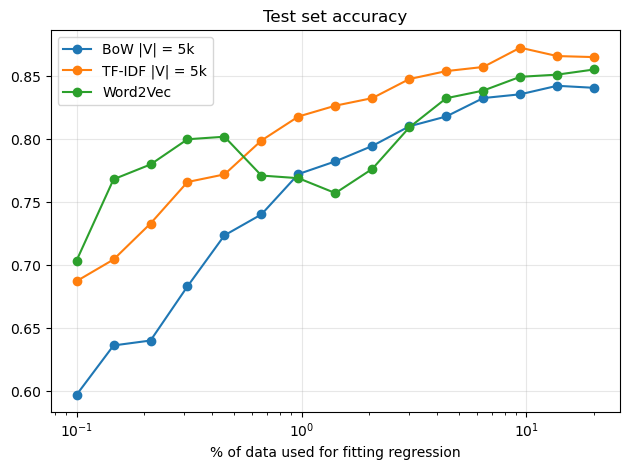

In [ ]:
import matplotlib.pyplot as plt 
x = np.array(train_size) * 100
plt.plot(x, test_accuracy_bow, "o-", label="BoW |V| = 5k")
plt.plot(x, test_accuracy_tf_idf, "o-", label="TF-IDF |V| = 5k")
plt.plot(x, test_accuracy_w2v, "o-", label="Word2Vec")
plt.title("Test set accuracy")
plt.xlabel("% of data used for fitting regression")
plt.grid(alpha=0.3)
plt.xscale("log", base=10)
plt.legend()
plt.tight_layout()
plt.show()

Here is a plot with training size (%age of whole dataset which is 60k samples) against test accuracy. 
It looks like W2V encoding (with mean pooling) is not that much efficient even with train size = 1% (600 samples)   

**Important** : Note that the vocabulary for BoW is learned from all the examples, which is kind of a data leakage and can explain why it's still so performant ! 

### A very important point of view : 

**learned embeddings followed by linear classifier is equivalent to BoW + (linear classifier of capped rank)**

indeed, if $x \in R^{|V|}$ is a BoW vector and $E = (e_1, ..., e_{|V|})$ learned embedding matrix (from W2V for example), mean pooling is exactly doing $h = \sum_{i = 1}^{|V|} x_j e_j \in \mathbb{R}^d$.  

Logistic regression on $h$ gives us $w \in \mathbb{R}^d$ (forget biais) such that $score(h) = w^Th = \sum_{j=1}^{|V|} x_j w^T e_j$.  

Define $\beta_j = w^T e_j$, we have $score(h) = \sum_{j=1}^{|V|} \beta_j x_j = <w, x>$ which is exactly fitting leasts squares on $x$ (BoW encoding) BUT with the condition $Wh$ = $WEx$ with $rg(WE) \leq rg(E) \leq d$ so constrained rank ! 


So yes "learned embeddings+linear is sightly less powerful than BoW+linear" BUT at least computationally we went from embedding dimension d = |V| ~ 5k to d = 300 ! 